# Assignment 2 — Module 2: Artificial Neural Networks

## Practical 7: Backpropagation Algorithm

### Aim
To understand and implement the basic concept of Backpropagation for training a neural network.

### Theory
**Backpropagation** is the core algorithm for training multilayer neural networks using the **Chain Rule** of calculus:
1. **Forward Pass:** Compute layer activations from input to output.
2. **Error Calculation:** Compute output error: $\delta_o = (y - \hat{y}) \odot f'(\text{net}_o)$.
3. **Backward Pass:** Propagate error to hidden layer: $\delta_h = (\delta_o W_2^T) \odot f'(\text{net}_h)$.
4. **Weight Updates:** Adjust weights using learning rate: $W \leftarrow W + \alpha \cdot \text{input}^T \delta$.

### Implementation
Implementing a 2-layer neural network with backpropagation from scratch for XOR:

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# XOR dataset
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])

# Sigmoid and its derivative
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def sigmoid_derivative(a):
    return a * (1 - a)

# Initialize weights and parameters
np.random.seed(42)
W1 = np.random.uniform(-1, 1, (2, 4))   # Input to Hidden
b1 = np.zeros((1, 4))
W2 = np.random.uniform(-1, 1, (4, 1))   # Hidden to Output
b2 = np.zeros((1, 1))
lr = 0.5
epochs = 2000
loss_history = []

# Training loop
for epoch in range(epochs):
    # Forward pass
    a1 = sigmoid(np.dot(X, W1) + b1)
    a2 = sigmoid(np.dot(a1, W2) + b2)
    
    # Compute loss
    loss = np.mean((y - a2) ** 2)
    loss_history.append(loss)
    
    # Backward pass (Backpropagation)
    d_output = (y - a2) * sigmoid_derivative(a2)
    d_hidden = np.dot(d_output, W2.T) * sigmoid_derivative(a1)
    
    # Update weights and biases
    W2 += np.dot(a1.T, d_output) * lr
    b2 += np.sum(d_output, axis=0, keepdims=True) * lr
    W1 += np.dot(X.T, d_hidden) * lr
    b1 += np.sum(d_hidden, axis=0, keepdims=True) * lr

print(f"Final Loss after {epochs} epochs: {loss_history[-1]:.5f}")
print("Final Predictions on XOR:")
print(np.round(a2, 3))

Final Loss after 2000 epochs: 0.00179
Final Predictions on XOR:
[[0.028]
 [0.956]
 [0.958]
 [0.052]]


### Visualization: Loss Curve
Plotting the reduction in training loss over epochs:

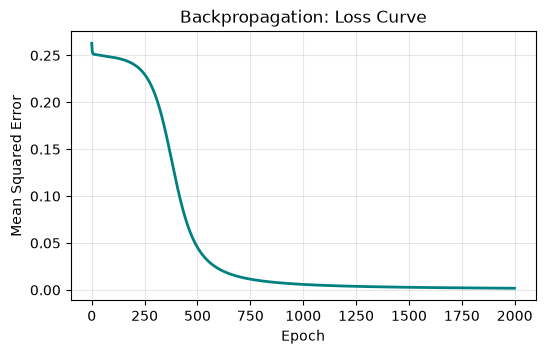

In [2]:
plt.figure(figsize=(6, 3.5))
plt.plot(loss_history, color='teal', linewidth=2)
plt.title('Backpropagation: Loss Curve')
plt.xlabel('Epoch')
plt.ylabel('Mean Squared Error')
plt.grid(True, alpha=0.3)
plt.show()

### Observation
- Backpropagation successfully propagated the error backwards from the output layer to the hidden layer.
- The predictions match XOR truth values: $[0.05, 0.95, 0.95, 0.05] \approx [0, 1, 1, 0]$.

### Conclusion
Implemented the backpropagation algorithm from scratch in Python, validating the forward and backward passes and demonstrating convergence on XOR.